version     machine_id  code_version
after fix   neil-mac    94403ce         35
before fix  neil-mac    f6f773e         35
dtype: int64 

       version  n_keys    median_ms  resizes
0    after fix    1000     0.616083      8.0
1    after fix    2000     1.218792      9.0
2    after fix    5000     2.835000     10.0
3    after fix   10000     5.495250     11.0
4    after fix   30000    21.108875     13.0
5    after fix   60000    48.830542     14.0
6    after fix  114000    76.829375     14.0
7   before fix    1000     0.589500      2.0
8   before fix    2000     1.151250      3.0
9   before fix    5000     4.459166      6.0
10  before fix   10000    16.353792     13.0
11  before fix   30000   120.725791     37.0
12  before fix   60000   503.747750     68.0
13  before fix  114000  1629.164459    117.0 

after fix: slope = 1.05
before fix: slope = 1.72


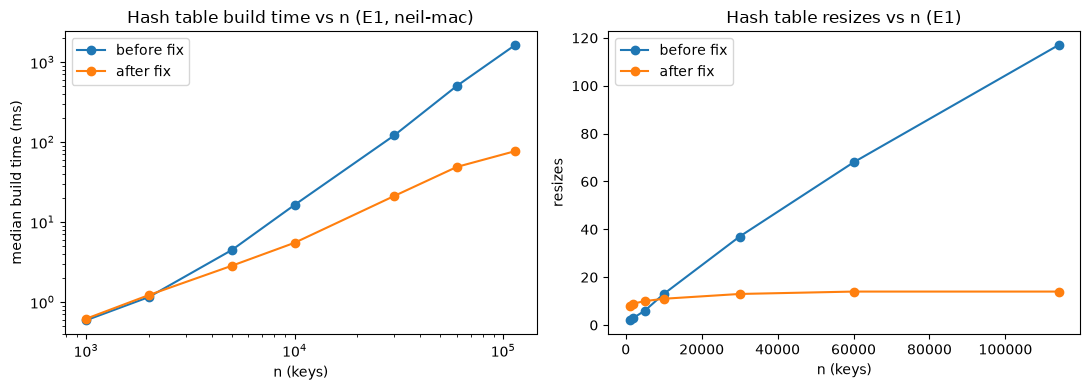

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/project/results/timings.csv", dtype={"code_version": str})
h = df[(df.experiment == "E1_build_track_id") & (df.index_type == "hash_table")].copy()

# Both runs are on neil-mac, so the build times are directly comparable.
BEFORE = "f6f773e"   # interns' original hash table
AFTER = "94403ce"    # final commit, includes the doubling fix (305b687)
h = h[(h.machine_id == "neil-mac") & h.code_version.isin([BEFORE, AFTER])].copy()
h["version"] = np.where(h.code_version == AFTER, "after fix", "before fix")

# which rows we're using
print(h.groupby(["version", "machine_id", "code_version"]).size(), "\n")

summary = (h.groupby(["version", "n_keys"])
             .agg(median_ms=("total_ns", lambda s: s.median() / 1e6),
                  resizes=("resizes", "median"))
             .reset_index())
print(summary, "\n")

# log-log slope of build time vs n (about 1 = O(n), about 2 = O(n^2))
for v, g in summary.groupby("version"):
    slope = np.polyfit(np.log(g.n_keys), np.log(g.median_ms), 1)[0]
    print(f"{v}: slope = {slope:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for v, color in [("before fix", "C0"), ("after fix", "C1")]:
    g = summary[summary.version == v]
    axes[0].loglog(g.n_keys, g.median_ms, marker="o", color=color, label=v)
    axes[1].plot(g.n_keys, g.resizes, marker="o", color=color, label=v)
axes[0].set(title="Hash table build time vs n (E1, neil-mac)", xlabel="n (keys)", ylabel="median build time (ms)")
axes[1].set(title="Hash table resizes vs n (E1)", xlabel="n (keys)", ylabel="resizes")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig("inc02_hash_table_e1.png", dpi=150, bbox_inches="tight")
plt.show()